# Proportional Clearing

## From balance sheets to clearing payments

For $n$ institutions, let total nominal liabilities be $\overline p\in\mathbb R_+^n$, external assets be $e\in\mathbb R_+^n$, and relative liabilities be $\Pi\in\mathbb R_+^{n\times n}$. The entry $\Pi_{ij}$ is the share of institution $i$'s total payment sent to institution $j$. The missing row mass is paid outside the network.

The basic proportional clearing equation is

$$
p=\min\!\left(\overline p,\ e+\Pi^{\mathsf T}p\right),
$$

where the minimum is taken component by component. The vector $p$ contains total payments, $\overline p$ contains promised payments, $e$ contains assets from outside the network, and $\Pi^{\mathsf T}p$ contains payments received from other institutions. Limited liability prevents an institution from paying more than its available resources, while the upper bound prevents it from paying more than it owes.

### Small network examples

Row,Symbol,Description
,String,String
1,pbar,Total nominal liabilities
2,e,External assets
3,Pi,Relative liabilities inside the network
4,p,Clearing payments
5,pbar - p,Unpaid nominal liabilities
6,1 - row sum of Pi,Share paid outside the network


Row,Example,Institution,External assets,Nominal liabilities,Clearing payment,Unpaid liabilities
,String,Int64,Float64,Float64,Float64,Float64
1,Two institutions,0,1.0,10.0,1.33333,8.66667
2,Two institutions,1,0.0,10.0,0.666667,9.33333
3,Three institution chain,0,3.0,5.0,3.0,2.0
4,Three institution chain,1,0.0,4.0,3.0,1.0
5,Three institution chain,2,0.0,2.0,2.0,0.0


Row,Example,Maximum fixed point residual,Payment bounds pass,Expected vector pass
,String,Float64,String,String
1,Two institutions,3.33067e-15,Pass,Pass
2,Three institution chain,1.77636e-15,Pass,Pass


Row,Example,Institution,External assets,Incoming payment,Available resources,Clearing payment
,String,Int64,Float64,Float64,Float64,Float64
1,Two institutions,0,1.0,0.333333,1.33333,1.33333
2,Two institutions,1,0.0,0.666667,0.666667,0.666667
3,Three institution chain,0,3.0,0.0,3.0,3.0
4,Three institution chain,1,0.0,3.0,3.0,3.0
5,Three institution chain,2,0.0,3.0,3.0,2.0


GKS: could not find font bold.ttf


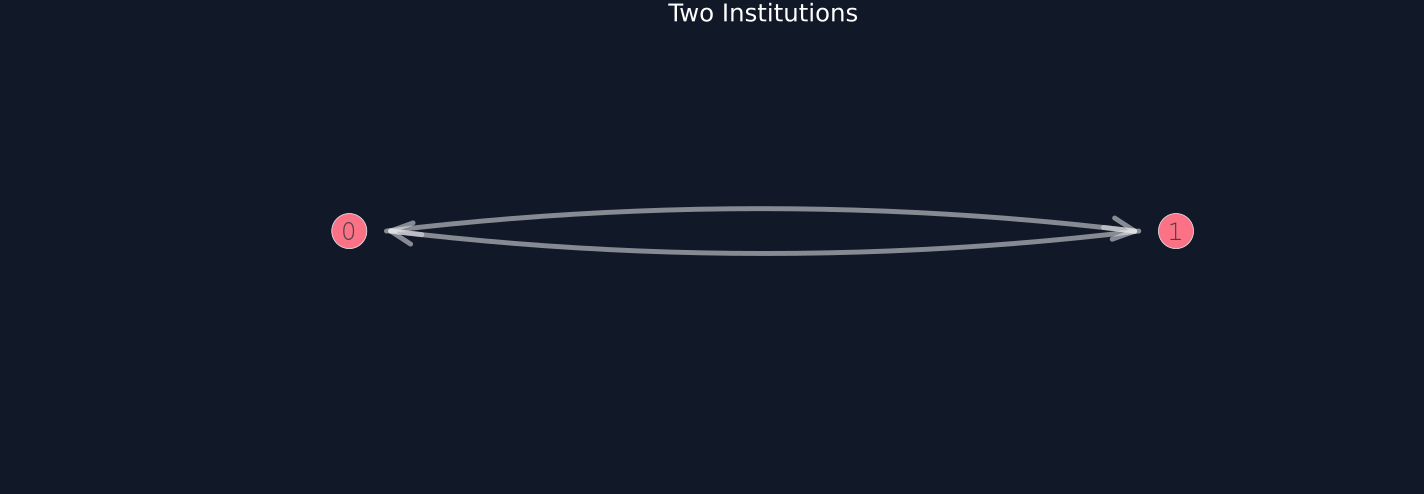

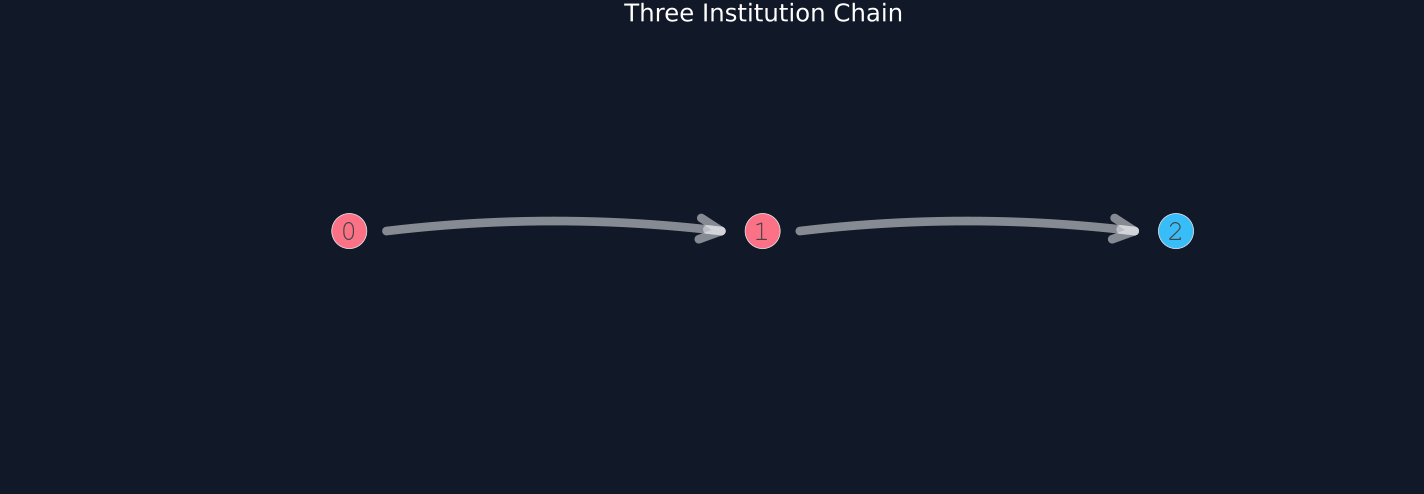

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("28_network_clearing");
using CSV, TOML, Printf, JuMP, Clarabel
include(joinpath("..","support","BookClearing.jl"))
using .BookClearing
using RiskLabAI.Optimization: eisenberg_noe_clearing
default(left_margin=12Plots.mm,bottom_margin=10Plots.mm)
violet = "#C084FC"
function table(frame,name,caption)
    shown = copy(frame)
    for column in names(shown)
        if eltype(shown[!,column])<:Bool
            shown[!,column] = ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter29-"*replace(name,"_"=>"-"))
    return nothing
end
random_root = joinpath("..","data","chapter28_random_inputs")
random_manifest = TOML.parsefile(joinpath(random_root,"inputs.toml"))["files"]
function primitive(name)
    path = joinpath(random_root,name)
    return Matrix{Float64}(CSV.read(path,DataFrame))
end
function network_positions(name,n)
    circle(count,radius,cx=0.0) = []
    n<=3 && return [(x,0.0) for x in range(-1,1;length=n)]
    name in ["Ring","Complete"] && return circle(n,1.0)
    name=="Core-periphery" && return vcat(circle(4,0.45),circle(n-4,1.0))
    return vcat(circle(n÷2,0.55,-0.7),circle(n-n÷2,0.55,0.7))
end
function plot_network(relative,name,stem,node_values=ones(size(relative,1)))
    n = size(relative,1)
    positions = network_positions(name,n)
    figure = plot(;title=name,aspect_ratio=:equal,axis=false,grid=false,legend=false,size=n<=3 ? (950,330) : (950,720),xlims=(-1.5,1.5),ylims=n<=3 ? (-0.35,0.35) : (-1.25,1.25))
    edge_rows = NamedTuple[]
    for debtor in 1:n,creditor in 1:n
        weight = relative[debtor,creditor]
        weight>1e-12 || continue
        push!(edge_rows,(Debtor=debtor-1,Creditor=creditor-1,relative=weight))
        start,stop = collect(positions[debtor]),collect(positions[creditor])
        direction = (stop-start)/norm(stop-start)
        start,stop = start+0.09direction,stop-0.10direction
        midpoint = (start+stop)/2+0.06norm(stop-start)*[-direction[2],direction[1]]
        curve = reduce(hcat,[(1-t)^2*start+2t*(1-t)*midpoint+t^2*stop for t in range(0,1;length=25)])
        plot!(figure,curve[1,:],curve[2,:];color="#E5E7EB",alpha=0.55,linewidth=0.8+5weight,arrow=true)
    end
    colors = [value>1e-8 ? palette.rose : palette.cyan for value in node_values]
    scatter!(figure,first.(positions),last.(positions);color=colors,markersize=13,markerstrokecolor="#E5E7EB",markerstrokewidth=0.8)
    for i in 1:n
        annotate!(figure,positions[i]...,text(string(i-1),10,"#111827",:bold))
    end
    save_figure(figure,paths,stem)
    edges = DataFrame(edge_rows)
    rename!(edges,["Debtor","Creditor","Relative liability"])
    save_data(edges,paths,stem)
    return nothing
end
function direct_linear_program(assets,nominal,relative)
    n = length(nominal)
    model = Model(Clarabel.Optimizer)
    set_silent(model)
    for name in ("tol_gap_abs","tol_gap_rel","tol_feas")
        set_optimizer_attribute(model,name,1e-14)
    end
    @variable(model,0<=payments[i=1:n]<=nominal[i])
    @constraint(model,(I-relative')*payments.<=min.(assets,nominal))
    @objective(model,Max,sum(payments))
    optimize!(model)
    @assert termination_status(model)==JuMP.MOI.OPTIMAL
    return value.(payments)
end
majorizes(source,target;tolerance=1e-12) = all(cumsum(sort(source;rev=true))[1:end-1].>=cumsum(sort(target;rev=true))[1:end-1].-tolerance)&&isapprox(sum(source),sum(target);atol=tolerance)
notation = DataFrame("Symbol"=>["pbar","e","Pi","p","pbar - p","1 - row sum of Pi"],"Description"=>["Total nominal liabilities","External assets","Relative liabilities inside the network","Clearing payments","Unpaid nominal liabilities","Share paid outside the network"])
table(notation,"clearing_notation","Notation for the basic proportional clearing model.")
examples = ["Two institutions"=>(external=[1.0,0.0],liabilities=[10.0,10.0],relative=[0.0 0.5;0.5 0.0],expected=[4/3,2/3]),"Three institution chain"=>(external=[3.0,0.0,0.0],liabilities=[5.0,4.0,2.0],relative=[0.0 1.0 0.0;0.0 0.0 1.0;0.0 0.0 0.0],expected=[3.0,3.0,2.0])]
result_rows,fixed_rows,flow_rows = NamedTuple[],NamedTuple[],NamedTuple[]
for (name,values) in examples
    payments = eisenberg_noe_clearing(values.external,values.liabilities,values.relative)
    available = values.external+values.relative'*payments
    fixed = min.(values.liabilities,available)
    @assert all(isapprox.(payments,values.expected;atol=1e-10))
    for institution in eachindex(payments)
        push!(result_rows,(Example=name,Institution=institution-1,external=values.external[institution],nominal=values.liabilities[institution],payment=payments[institution],unpaid=values.liabilities[institution]-payments[institution]))
        push!(flow_rows,(Example=name,Institution=institution-1,external=values.external[institution],incoming=(values.relative'*payments)[institution],available=available[institution],payment=payments[institution]))
    end
    push!(fixed_rows,(Example=name,residual=maximum(abs.(payments-fixed)),bounds=all(payments.>=0)&&all(payments.<=values.liabilities.+1e-12),expected=all(isapprox.(payments,values.expected;atol=1e-10))))
end
exact_results = DataFrame(result_rows)
rename!(exact_results,["Example","Institution","External assets","Nominal liabilities","Clearing payment","Unpaid liabilities"])
table(exact_results,"exact_network_results","Hand-checkable clearing payments and unpaid liabilities.")
fixed_checks = DataFrame(fixed_rows)
rename!(fixed_checks,["Example","Maximum fixed point residual","Payment bounds pass","Expected vector pass"])
table(fixed_checks,"clearing_fixed_point_checks","Fixed point and payment-bound checks for the exact examples.")
flow = DataFrame(flow_rows)
rename!(flow,["Example","Institution","External assets","Incoming payment","Available resources","Clearing payment"])
table(flow,"payment_flow_decomposition","External assets, incoming payments, and available resources.")
for (name,values,stem) in [("Two Institutions",examples[1].second,"two_node_clearing_network"),("Three Institution Chain",examples[2].second,"three_node_clearing_network")]
    payments = eisenberg_noe_clearing(values.external,values.liabilities,values.relative)
    plot_network(values.relative,name,stem,values.liabilities-payments)
end


## Independently checking the greatest clearing payment

Starting from promised payments, the monotone update is

$$
p^{(k+1)}=\min\!\left(\overline p,\ e+\Pi^{\mathsf T}p^{(k)}\right),
\qquad p^{(0)}=\overline p.
$$

Here, $p^{(k)}$ is the payment vector after update $k$. Starting from the upper bound makes the sequence nonincreasing. In the basic finite examples below, its limit agrees with both the released RiskLabAI result and a separate linear program that maximizes the sum of feasible payments.

Row,Example,Iteration steps,Released versus iteration residual,Released versus direct LP residual,Sum of released payments,Pass
,String,Int64,Float64,Float64,Float64,String
1,Two institutions,44,5.24469e-13,6.43929e-15,2.0,Pass
2,Three institution chain,3,2.66454e-15,2.66454e-15,8.0,Pass


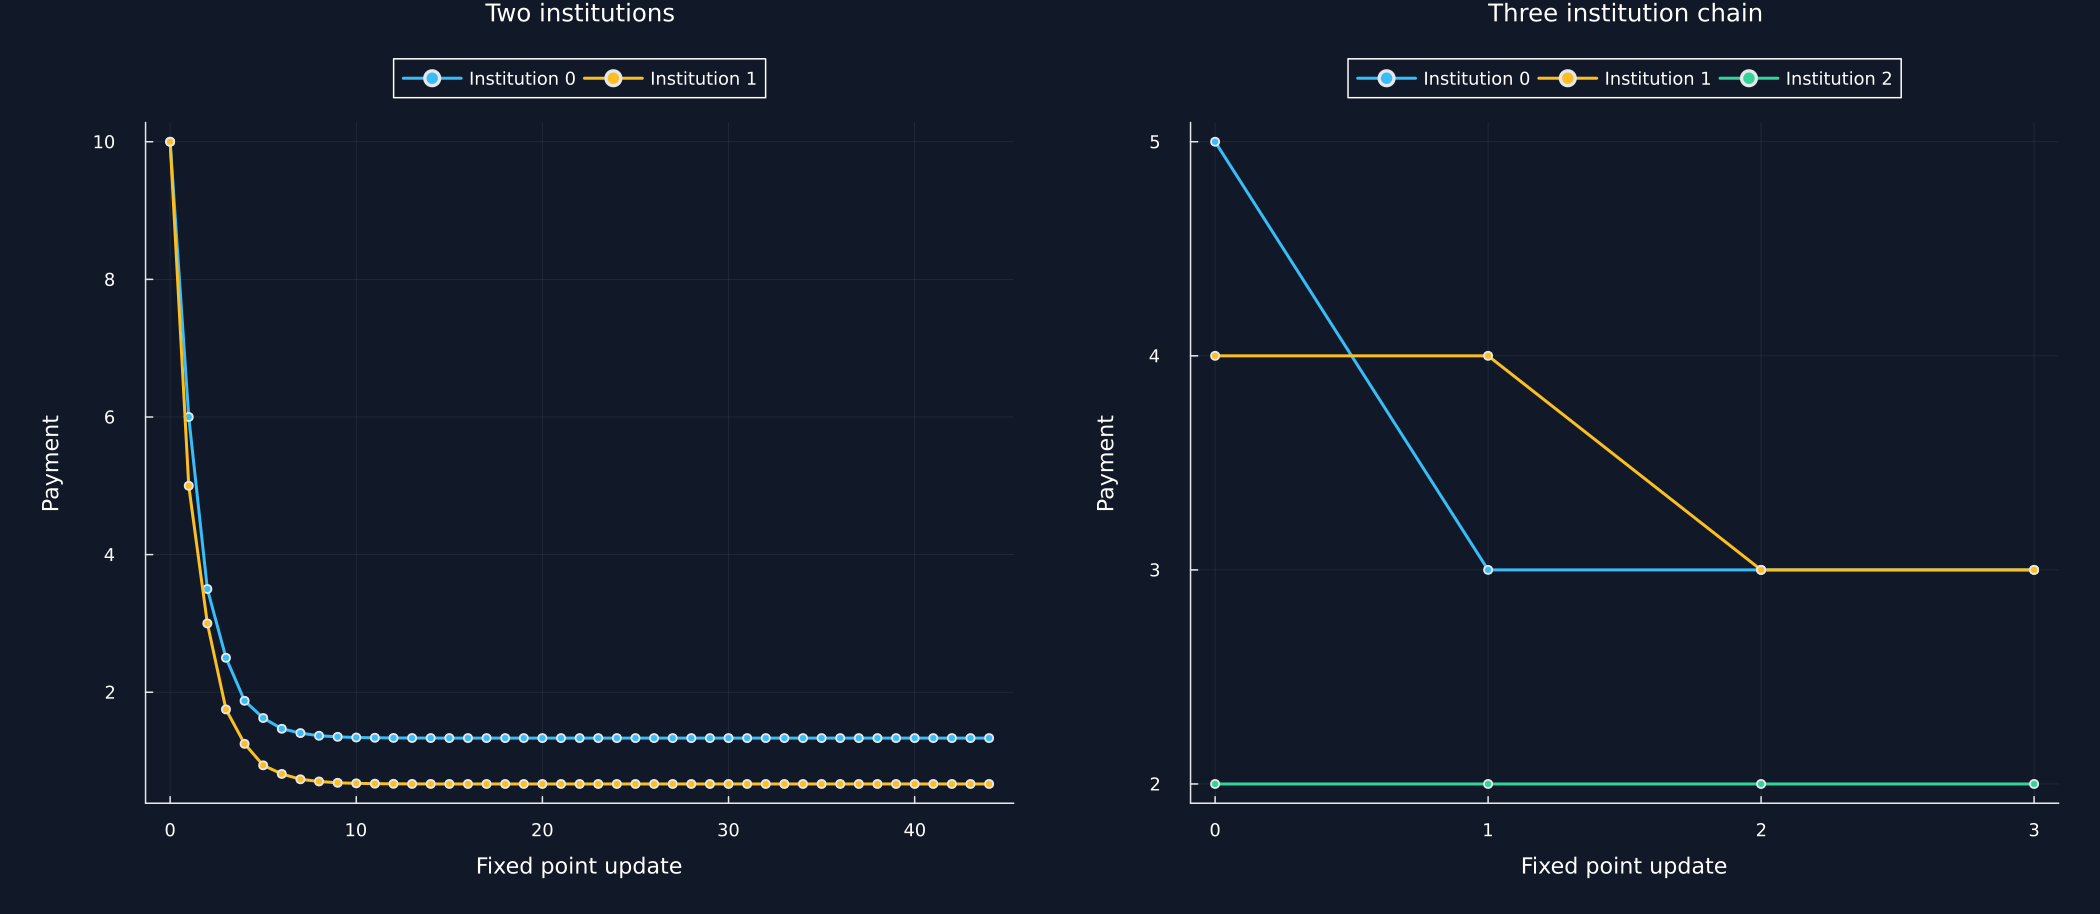

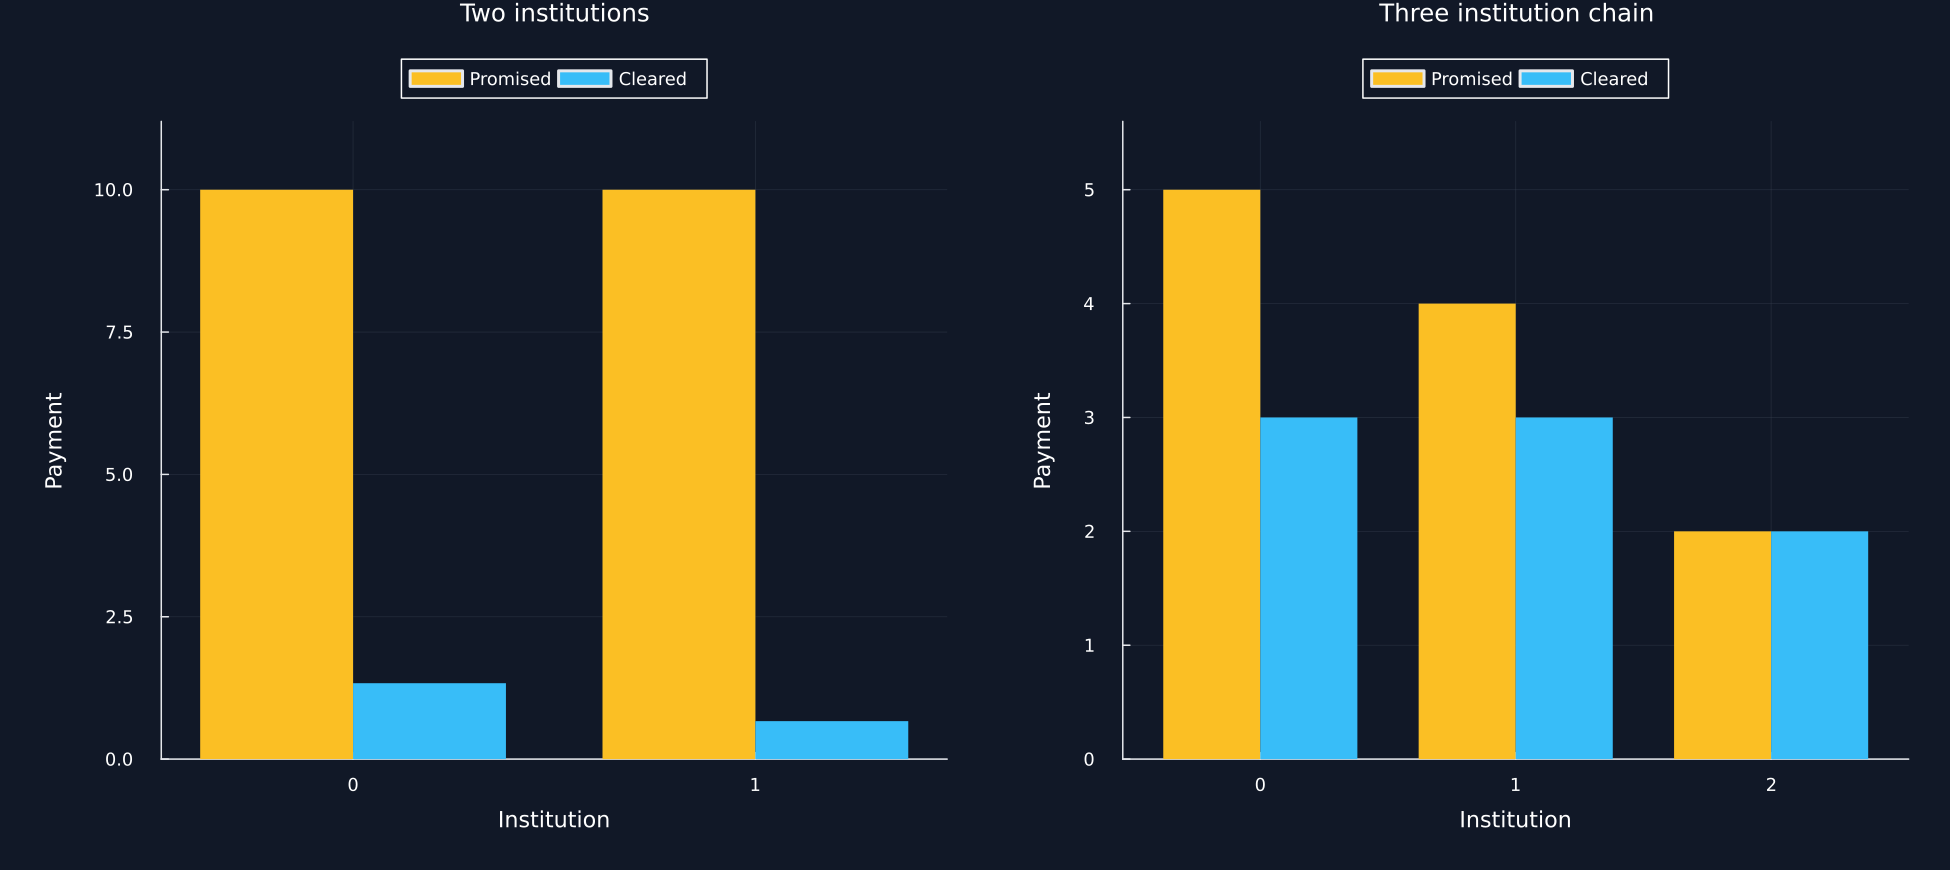

In [2]:
comparison_rows,iteration_rows = NamedTuple[],NamedTuple[]
for (name,values) in examples
    released = eisenberg_noe_clearing(values.external,values.liabilities,values.relative)
    iterated,history = greatest_iteration(values.external,values.liabilities,values.relative)
    direct = direct_linear_program(values.external,values.liabilities,values.relative)
    passed = all(isapprox.(released,iterated;atol=1e-10))&&all(isapprox.(released,direct;atol=1e-10))
    push!(comparison_rows,(Example=name,steps=size(history,1)-1,iteration=maximum(abs.(released-iterated)),direct=maximum(abs.(released-direct)),total=sum(released),Pass=passed))
    for step in axes(history,1),institution in axes(history,2)
        push!(iteration_rows,(Example=name,Step=step-1,Institution=institution-1,Payment=history[step,institution]))
    end
end
method_checks = DataFrame(comparison_rows)
rename!(method_checks,["Example","Iteration steps","Released versus iteration residual","Released versus direct LP residual","Sum of released payments","Pass"])
@assert all(method_checks.Pass)
table(method_checks,"independent_method_checks","Agreement with monotone iteration and a separate linear program.")
iteration_data = DataFrame(iteration_rows)
save_data(iteration_data,paths,"clearing_iteration_paths")
panels = Any[]
for (name,values) in examples
    part = iteration_data[iteration_data.Example.==name,:]
    panel = plot(;title=name,xlabel="Fixed point update",ylabel="Payment",legend=:outertop,legend_columns=length(values.external))
    for (institution,color) in zip(0:length(values.external)-1,[palette.cyan,palette.amber,palette.green])
        line = part[part.Institution.==institution,:]
        plot!(panel,line.Step,line.Payment;color,marker=:circle,markersize=3,label="Institution "*string(institution))
    end
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(1,2),size=(1400,610)),paths,"clearing_iteration_paths")
payment_plot = exact_results[:,["Example","Institution","Nominal liabilities","Clearing payment"]]
save_data(payment_plot,paths,"promised_and_cleared_payments")
panels = Any[]
for (name,_) in examples
    part = payment_plot[payment_plot.Example.==name,:]
    x = part.Institution
    panel = bar(x.-0.19,part[!,"Nominal liabilities"];bar_width=0.38,color=palette.amber,label="Promised",linealpha=0,xticks=(x,string.(x)),xlabel="Institution",ylabel="Payment",title=name,legend=:outertop,legend_columns=2,ylims=(0,1.12maximum(part[!,"Nominal liabilities"])))
    bar!(panel,x.+0.19,part[!,"Clearing payment"];bar_width=0.38,color=palette.cyan,label="Cleared",linealpha=0)
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(1,2),size=(1300,580)),paths,"promised_and_cleared_payments")


## Checking clearing-model boundaries

If every monetary input is multiplied by a positive scale $a$, the clearing payments should satisfy

$$
p(ae,a\overline p,\Pi)=a\,p(e,\overline p,\Pi).
$$

The scalar $a$ changes the unit of account, while the relative-liability matrix stays unchanged. This identity is checked at very small, ordinary, and very large scales. Invalid shapes, negative values, nonfinite values, and rows whose internal shares exceed one are rejected explicitly.

In [3]:
base = examples[1].second
base_payment = eisenberg_noe_clearing(base.external,base.liabilities,base.relative)
scale_rows = NamedTuple[]
for scale in [1e-12,1.0,1e12]
    external,nominal,relative = base.external*scale,base.liabilities*scale,copy(base.relative)
    before = (copy(external),copy(nominal),copy(relative))
    payment = eisenberg_noe_clearing(external,nominal,relative)
    push!(scale_rows,(Scale=scale,error=maximum(abs.(payment/scale-base_payment)),preserved=before==(external,nominal,relative),Pass=all(isapprox.(payment/scale,base_payment;atol=1e-10))))
end
scaling = DataFrame(scale_rows)
rename!(scaling,["Scale","Maximum normalized error","Inputs preserved","Pass"])
@assert all(scaling.Pass)&&all(scaling[!,"Inputs preserved"])
table(scaling,"scaling_checks","Monetary scaling and input-preservation checks.")
invalid_cases = [("Empty system",Float64[],Float64[],zeros(0,0)),("Asset vector has two dimensions",reshape([1.0],1,1),[1.0],zeros(1,1)),("Negative external asset",[-1.0],[1.0],zeros(1,1)),("Nonfinite liability",[1.0],[Inf],zeros(1,1)),("Internal row sum exceeds one",[1.0],[1.0],fill(1.01,1,1))]
invalid_rows = NamedTuple[]
for (case,external,nominal,relative) in invalid_cases
    rejected,error_name = try
        eisenberg_noe_clearing(external,nominal,relative)
        false,""
    catch error
        error isa ArgumentError,string(nameof(typeof(error)))
    end
    push!(invalid_rows,(Case=case,Rejected=rejected,Error=error_name))
end
invalid = DataFrame(invalid_rows)
@assert all(invalid.Rejected)
table(invalid,"invalid_input_checks","Explicit rejection checks for invalid clearing inputs.")
scope = DataFrame("Question"=>["Are payments proportional among a debtor's creditors?","Are payments capped by nominal liabilities?","Are bankruptcy costs included?","Are fire sales or price effects included?","Does a link identify a causal spillover?"],"Answer"=>["Yes","Yes","No","No","No"],"Boundary"=>["Fixed relative-liability rows","Limited liability and payment priority","Basic clearing model only","No asset-price feedback","Mathematical propagation only"])
table(scope,"clearing_scope_boundaries","Questions answered and not answered by the basic clearing calculation.")


Row,Scale,Maximum normalized error,Inputs preserved,Pass
,Float64,Float64,String,String
1,1.0e-12,0.0,Pass,Pass
2,1.0,0.0,Pass,Pass
3,1.0e12,0.0,Pass,Pass


Row,Case,Rejected,Error
,String,String,String
1,Empty system,Pass,ArgumentError
2,Asset vector has two dimensions,Pass,ArgumentError
3,Negative external asset,Pass,ArgumentError
4,Nonfinite liability,Pass,ArgumentError
5,Internal row sum exceeds one,Pass,ArgumentError


Row,Question,Answer,Boundary
,String,String,String
1,Are payments proportional among a debtor's creditors?,Yes,Fixed relative-liability rows
2,Are payments capped by nominal liabilities?,Yes,Limited liability and payment priority
3,Are bankruptcy costs included?,No,Basic clearing model only
4,Are fire sales or price effects included?,No,No asset-price feedback
5,Does a link identify a causal spillover?,No,Mathematical propagation only
